In [34]:
import numpy as np
import easyocr
import cv2
from matplotlib import pyplot as plt

In [35]:
MIN_BOX_LABEL = 4
INC_DEC_THRES = 3

BL_I = -600 # start bottom line 
BL_E = -440 # stop bottom line

LL_I = 0     # start left line  
LL_E = 250   # stop  left line

RL_I = -200

TL_I = 432
TL_E = 600

In [ ]:
def s3_detect(rgbImage):
    reader        = easyocr.Reader(['en'], gpu=False)
    blurred_image = cv2.GaussianBlur(rgbImage, (5, 5), 0)
    grayImage     = cv2.cvtColor(blurred_image, cv2.COLOR_BGR2GRAY)
    results       = reader.readtext(grayImage, low_text=0.3)

    #print(results)

    rtList = []

    for (bbox, text, confidence) in results:
        print("detecting ", text)
        (top_left, top_right, bottom_right, bottom_left) = bbox
        top_left     = tuple(map(int, top_left))
        bottom_right = tuple(map(int, bottom_right))
        top_right    = tuple(map(int, top_right))
        bottom_left  = tuple(map(int, bottom_left))

        x, y = (top_left[1] + bottom_right[1] + top_right[1] + bottom_left[1],
                top_left[0] + bottom_right[0] + top_right[0] + bottom_left[0]
                )
        x,y = x//4, y//4

        #### text, row, column
        rtList.append((text, x, y))
        #print((text, x, y))


    return rtList
    

def s3_filterNumber(rtList):
    NUMBER_LIST = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]
    return [(text, x, y) for text,x,y in rtList if text in NUMBER_LIST]

def s3_findMaxIncDecSubSeq(rtList, isInc):

    dp = [0 for _ in rtList]
    
    # sort by row
    sortedRtList = sorted(rtList, key=lambda item: item[1])

    for index, (text, x, y) in enumerate(sortedRtList):

        lb = int(text)

        for oldIndex, (oldText, _, _) in enumerate(sortedRtList[0: index]):
            oldLb = int(oldText)
            if ( (isInc and (lb > oldLb)) or 
                 ((not isInc) and (lb < oldLb))):
                dp[index] = max(dp[index], dp[oldIndex] + 1)
    
    return max(dp)



# return none for not detect system
def s3_check(rtList):

    rtList = s3_filterNumber(rtList)

    if len(rtList) < MIN_BOX_LABEL:
        print("s3: label quan is not sufficient enough")
        return None
    
    # check inc

    if s3_findMaxIncDecSubSeq(rtList, True) >= INC_DEC_THRES:
        print("s3: label is sufficient for inc order")
        return True
    
    print("s3: label is not sufficient for inc order try dec")

    if s3_findMaxIncDecSubSeq(rtList, False) >= INC_DEC_THRES:
        print("s3: label is sufficient for inc order")
        return False
    
    print("s3: no order suffient enough")
    return None

# amount rotation require
def s3_start(rgbImage):
    
    plt.figure(1)
    plt.imshow(rgbImage[:, LL_I:LL_E,:], label='left check')
    plt.title('left check')
    plt.figure(2)
    plt.imshow(rgbImage[BL_I:BL_E, :,:], label='bottom check')
    plt.title('bottomCheck')
    plt.show()
    plt.figure(3)
    plt.imshow(rgbImage[:, RL_I::,:], label='right check')
    plt.title('right')
    plt.show()
    plt.figure(4)
    plt.imshow(rgbImage[TL_I:TL_E, :,:], label='top check')
    plt.title('top')
    plt.show()
    
    print("check left result border")
    left_rtList = s3_detect(rgbImage[:, LL_I:LL_E,:])
    #print("left_rtList", left_rtList)
    left_order = s3_check(left_rtList)

    if (left_order != None):
        return 0 if left_order else 2
    
    print("check bottom result border")
    
    bottom_rotated_image = cv2.rotate(rgbImage[BL_I:BL_E, :,:], cv2.ROTATE_90_CLOCKWISE)
    bottom_rtList        = s3_detect(bottom_rotated_image)
    bottom_order         = s3_check(bottom_rtList)

    if (bottom_order != None):
        return 1 if bottom_order else 3
    
    print("check right result border")

    right_rotated_image = cv2.rotate(rgbImage[:, -200::,:], cv2.ROTATE_180)
    right_rtList        = s3_detect(right_rotated_image)
    right_order         = s3_check(right_rtList)

    if (right_order != None):
        return 2 if right_order else 4
    
    print("check top result border")

    top_rotated_image = cv2.rotate(rgbImage[TL_I:TL_E,:,:], cv2.ROTATE_90_COUNTERCLOCKWISE)
    top_rtList        = s3_detect(top_rotated_image)
    top_order         = s3_check(top_rtList)

    if (top_order != None):
        return 3 if top_order else 1
    
    
    
    print("cannot dectect any order")

    return 0


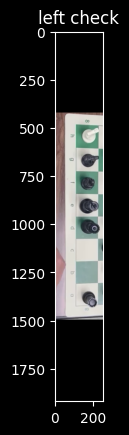

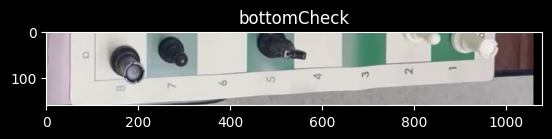

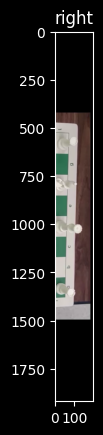

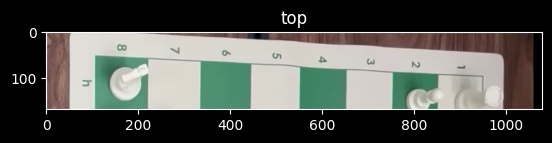

Using CPU. Note: This module is much faster with a GPU.


check left result border


Using CPU. Note: This module is much faster with a GPU.


detecting  T
s3: label quan is not sufficient enough
check bottom result border


Using CPU. Note: This module is much faster with a GPU.


detecting  5
detecting  2
s3: label quan is not sufficient enough
check right result border


Using CPU. Note: This module is much faster with a GPU.


s3: label quan is not sufficient enough
check top result border
detecting  2
detecting  3
detecting  5
detecting  7
detecting  8
detecting  h
s3: label is sufficient for inc order
3


In [38]:
image = cv2.imread("examplePic/2_Move_rotate_student_rotate.png")
print(s3_start(image[:,:,::-1]))